In [1]:
import os
import warnings
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
os.makedirs("outputs/data", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)

# Primary pre-monsoon fieldwork dataset digitized from BSc Geology Project Report (Nov 2023)
# Study area: Bari Brahmana industrial corridor, Samba District, J&K (32.6417°N, 74.9250°E)
# QA fixes documented from printed Table 2:
#   1. Sample 10 Fe typo '02' corrected to 0.2 mg/L (matches printed mean 0.13 mg/L & text 0.1-0.2 mg/L)
#   2. Column label 'Cr' standardized to Cl_mg_L (Chloride, 120-260 mg/L)
raw_records = [
    (1,  "Ranjari",                      "Tube well", 0.1, 18, 0.30, 180, 410, 210,  75, 0.2, 7.2, 2.60, 190),
    (2,  "Raya Old",                     "Tube well", 0.2, 14, 0.80, 160, 420, 170,  60, 0.2, 7.3, 2.30, 160),
    (3,  "Smailpur Christian Mohalla",   "Tube well", 0.1, 15, 0.50, 180, 430, 140,  60, 0.2, 7.3, 2.40, 180),
    (4,  "Saraswati Agro Chemicals",     "Tube well", 0.1, 12, 0.50, 220, 480, 190,  65, 0.2, 7.2, 2.10, 190),
    (5,  "Patti",                        "Hand pump", 0.2, 40, 0.90, 260, 600, 240,  90, 0.2, 7.6, 3.40, 210),
    (6,  "Dhyansar",                     "Tube well", 0.1, 15, 0.70, 140, 440, 180,  60, 0.2, 7.3, 2.40, 180),
    (7,  "SIDCO Estate Office",          "Borewell",  0.1, 18, 0.65, 120, 430, 170,  50, 0.2, 7.4, 2.10, 170),
    (8,  "Steel Factory",                "Borewell",  0.1, 10, 0.40, 170, 410, 120,  40, 0.2, 7.1, 2.10, 130),
    (9,  "Khidyaan, Badhori",            "Hand pump", 0.1, 65, 0.12, 250, 640, 260, 100, 0.2, 7.6, 3.60, 220),
    (10, "Furniture Factory",            "Borewell",  0.2, 15, 0.40, 120, 480, 190,  60, 0.2, 7.3, 2.60, 190),
]

columns = [
    "sample_id", "location", "source_type", "Fe", "NO3", "F", "Cl",
    "TDS", "Alkalinity", "Ca", "Residual_Cl", "pH", "Turbidity", "Hardness"
]
df = pd.DataFrame(raw_records, columns=columns)

# Classify aquifer access depth group
df["aquifer_zone"] = df["source_type"].apply(
    lambda x: "Shallow (Hand Pump)" if x == "Hand pump" else "Deeper (Tube/Borewell)"
)

# Save clean primary CSV for GitHub
df.to_csv("outputs/data/bari_brahmana_groundwater_2023.csv", index=False)

# Reproducibility check against Table 2 printed means
num_cols = ["Fe", "NO3", "F", "Cl", "TDS", "Alkalinity", "Ca", "Residual_Cl", "pH", "Turbidity", "Hardness"]
print("=== Verification Check: Computed Means vs. 2023 Report Table 2 ===")
display(df[num_cols].agg(["mean", "min", "max"]).round(2))
print("Clean dataset saved to outputs/data/bari_brahmana_groundwater_2023.csv")

=== Verification Check: Computed Means vs. 2023 Report Table 2 ===


,Fe,NO3,F,Cl,TDS,Alkalinity,Ca,Residual_Cl,pH,Turbidity,Hardness
mean,0.13,22.2,0.53,180.0,474.0,187.0,66.0,0.2,7.33,2.56,182.0
min,0.10,10.0,0.12,120.0,410.0,120.0,40.0,0.2,7.10,2.10,130.0
max,0.20,65.0,0.90,260.0,640.0,260.0,100.0,0.2,7.60,3.60,220.0


Clean dataset saved to outputs/data/bari_brahmana_groundwater_2023.csv


In [2]:
from scipy.stats import mannwhitneyu

# 1. BIS IS 10500:2012 Drinking Water Benchmarks
BIS = {
    "Fe":         {"acc": 0.3,  "perm": 0.3,  "weight": 4, "unit": "mg/L"},
    "NO3":        {"acc": 45.0, "perm": 45.0, "weight": 5, "unit": "mg/L"},
    "F":          {"acc": 1.0,  "perm": 1.5,  "weight": 5, "unit": "mg/L"},
    "Cl":         {"acc": 250,  "perm": 1000, "weight": 3, "unit": "mg/L"},
    "TDS":        {"acc": 500,  "perm": 2000, "weight": 4, "unit": "mg/L"},
    "Alkalinity": {"acc": 200,  "perm": 600,  "weight": 2, "unit": "mg/L"},
    "Ca":         {"acc": 75,   "perm": 200,  "weight": 2, "unit": "mg/L"},
    "pH":         {"min": 6.5,  "max": 8.5,   "weight": 4, "unit": "pH"},
    "Turbidity":  {"acc": 1.0,  "perm": 5.0,  "weight": 3, "unit": "NTU"},
    "Hardness":   {"acc": 200,  "perm": 600,  "weight": 3, "unit": "mg/L"},
}

# 2. Health-Weighted Water Quality Index (WQI - Vasanthavigar et al., 2010 / BIS 10500:2012)
total_weight = sum(v["weight"] for v in BIS.values())
wqi_scores = []

for _, row in df.iterrows():
    si_sum = 0.0
    for param, cfg in BIS.items():
        Wi = cfg["weight"] / total_weight
        val = row[param]
        if param == "pH":
            qi = (abs(val - 7.0) / (8.5 - 7.0)) * 100.0
        else:
            qi = (val / cfg["acc"]) * 100.0
        si_sum += Wi * qi
    wqi_scores.append(round(si_sum, 2))

df["WQI"] = wqi_scores

def classify_wqi(val):
    if val < 50:   return "Excellent (<50)"
    if val < 100:  return "Good (50-100)"
    if val < 200:  return "Poor (100-200)"
    if val < 300:  return "Very Poor (200-300)"
    return "Unsuitable (>300)"

df["WQI_Class"] = df["WQI"].apply(classify_wqi)

# 3. BIS Two-Tier Compliance Matrix (0 = Acceptable, 1 = Above Acceptable, 2 = Above Permissible)
status_df = pd.DataFrame(index=df["location"])
for param, cfg in BIS.items():
    codes = []
    for val in df[param]:
        if param == "pH":
            codes.append(0 if (cfg["min"] <= val <= cfg["max"]) else 2)
        elif val > cfg["perm"]:
            codes.append(2)
        elif val > cfg["acc"]:
            codes.append(1)
        else:
            codes.append(0)
    status_df[param] = codes

# 4. Shallow Hand Pump vs. Deeper Well Comparison (Exploratory Mann-Whitney U)
shallow = df[df["aquifer_zone"] == "Shallow (Hand Pump)"]
deeper  = df[df["aquifer_zone"] == "Deeper (Tube/Borewell)"]

strat_rows = []
for p in ["NO3", "TDS", "Cl", "Alkalinity", "Ca", "Hardness", "Turbidity", "pH", "WQI"]:
    u_stat, p_val = mannwhitneyu(shallow[p], deeper[p], alternative="two-sided")
    strat_rows.append({
        "Parameter": p,
        "Shallow_Mean (n=2)": round(shallow[p].mean(), 2),
        "Deeper_Mean (n=8)": round(deeper[p].mean(), 2),
        "Ratio (Shallow/Deeper)": round(shallow[p].mean() / deeper[p].mean(), 2),
        "MannWhitney_p": round(p_val, 4),
    })

strat_df = pd.DataFrame(strat_rows)
df.to_csv("outputs/data/bari_brahmana_wqi_results.csv", index=False)
strat_df.to_csv("outputs/data/shallow_vs_deep_stratification.csv", index=False)

print("=== Site-Wise Water Quality Index (WQI) ===")
display(df[["sample_id", "location", "source_type", "NO3", "TDS", "WQI", "WQI_Class"]].sort_values("WQI", ascending=False))

print("\n=== Shallow Hand Pump vs. Deeper Well Hydrochemical Contrast ===")
display(strat_df)

=== Site-Wise Water Quality Index (WQI) ===


,sample_id,location,source_type,NO3,TDS,WQI,WQI_Class
4,5,Patti,Hand pump,40,600,112.23,Poor (100-200)
8,9,"Khidyaan, Badhori",Hand pump,65,640,109.26,Poor (100-200)
1,2,Raya Old,Tube well,14,420,76.86,Good (50-100)
9,10,Furniture Factory,Borewell,15,480,75.90,Good (50-100)
5,6,Dhyansar,Tube well,15,440,73.71,Good (50-100)
0,1,Ranjari,Tube well,18,410,73.02,Good (50-100)
3,4,Saraswati Agro Chemicals,Tube well,12,480,71.32,Good (50-100)
2,3,Smailpur Christian Mohalla,Tube well,15,430,70.86,Good (50-100)
6,7,SIDCO Estate Office,Borewell,18,430,69.75,Good (50-100)
7,8,Steel Factory,Borewell,10,410,58.71,Good (50-100)



=== Shallow Hand Pump vs. Deeper Well Hydrochemical Contrast ===


,Parameter,Shallow_Mean (n=2),Deeper_Mean (n=8),Ratio (Shallow/Deeper),MannWhitney_p
0,NO3,52.50,14.62,3.59,0.0467
1,TDS,620.00,437.50,1.42,0.0481
2,Cl,255.00,161.25,1.58,0.0488
3,Alkalinity,250.00,171.25,1.46,0.0488
4,Ca,95.00,58.75,1.62,0.0433
5,Hardness,215.00,173.75,1.24,0.0467
6,Turbidity,3.50,2.33,1.51,0.0460
7,pH,7.60,7.26,1.05,0.0420
8,WQI,110.74,71.27,1.55,0.0444


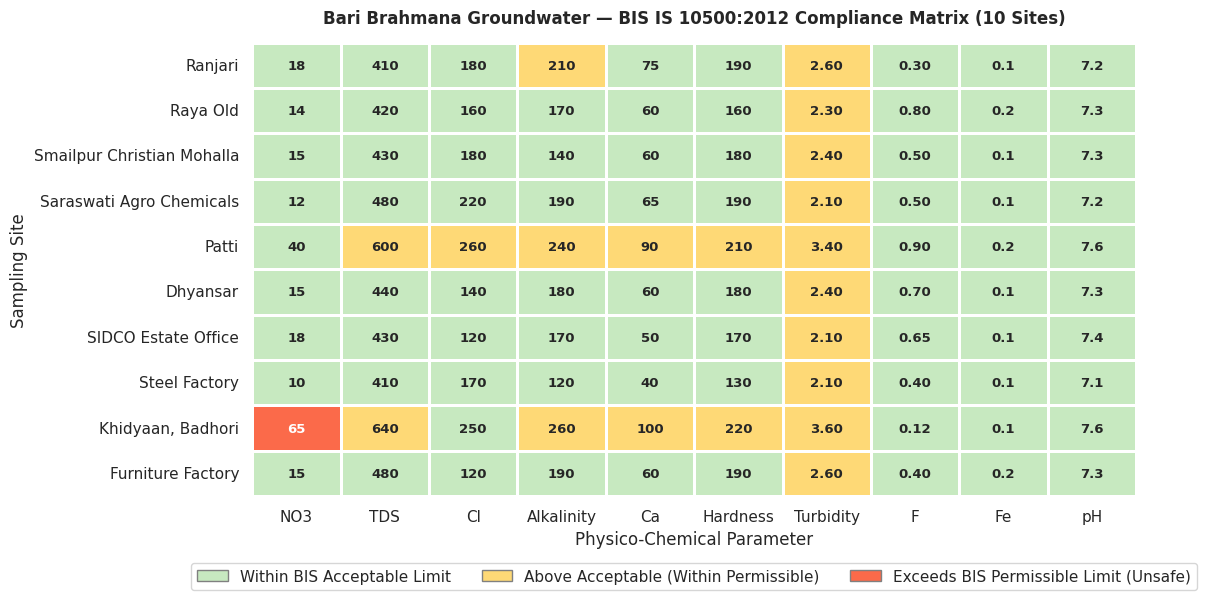

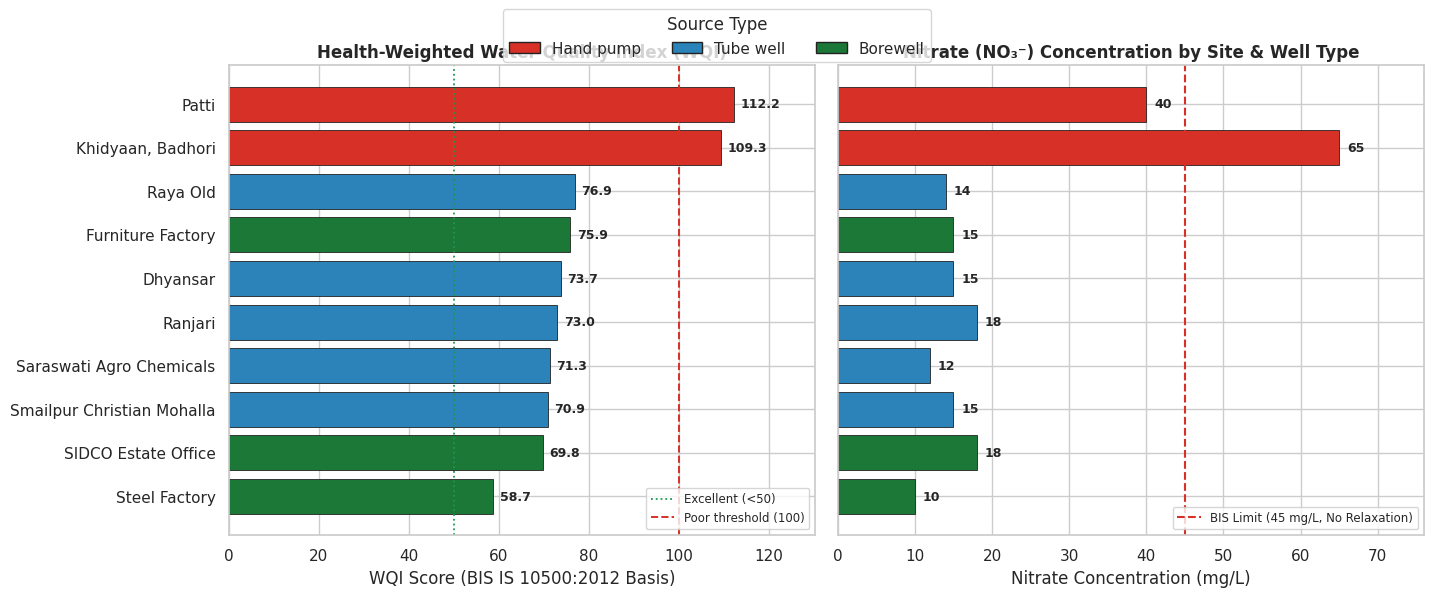

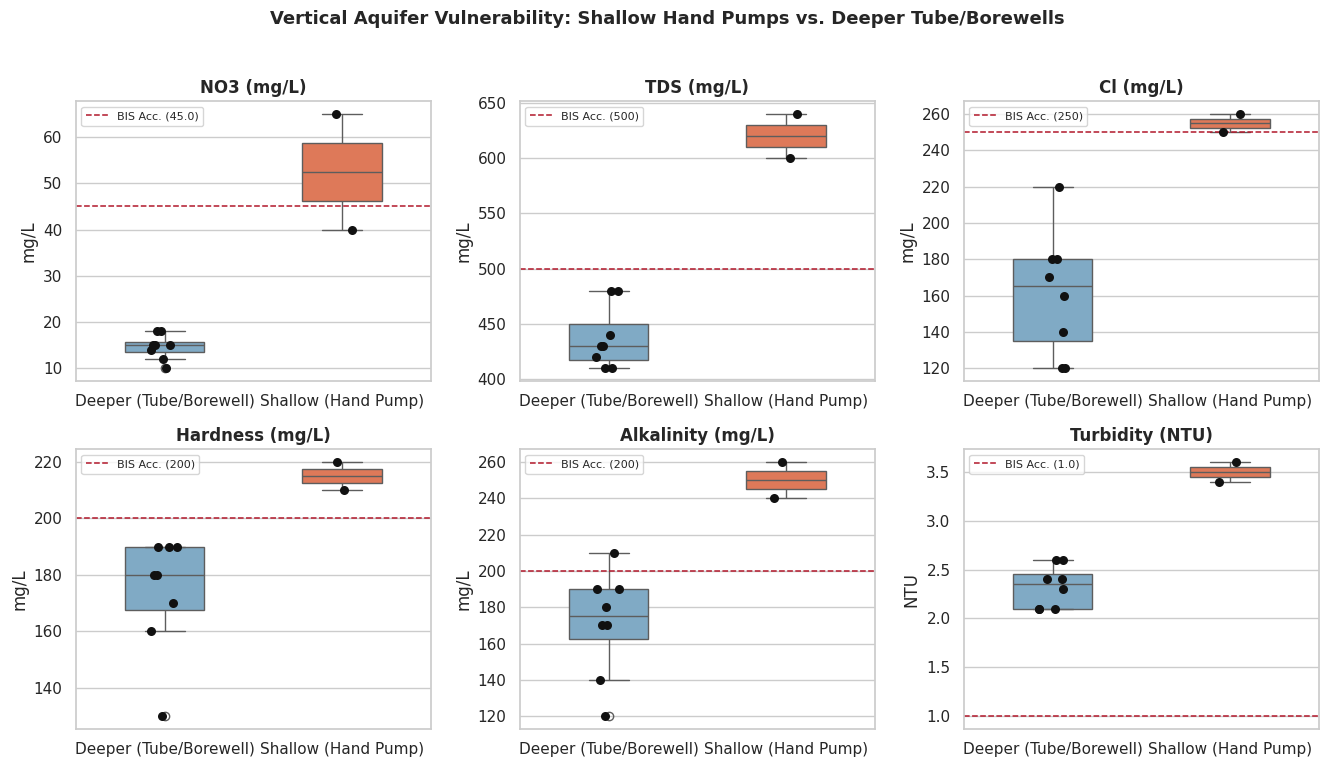

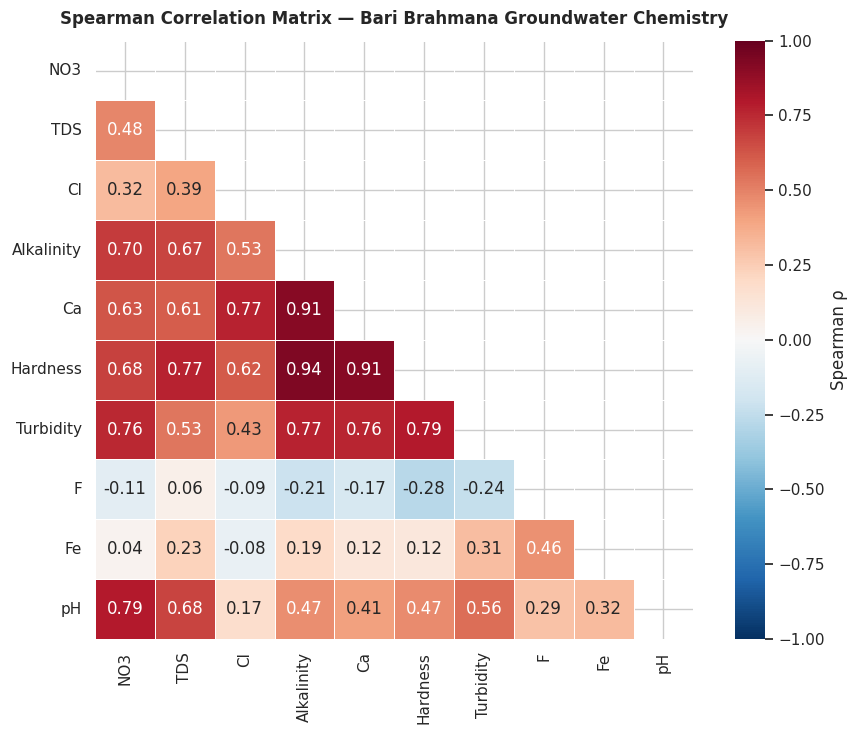


================ COPY THIS SUMMARY BACK TO ME ================
Total sites: 10 | Hand pumps: 2 | Tube wells: 5 | Borewells: 3
WQI Range: 58.71 (Steel Factory) to 112.23 (Patti)
WQI Classes: {'Good (50-100)': 8, 'Poor (100-200)': 2}
Shallow Hand Pump Mean WQI: 110.75 vs Deeper Wells Mean WQI: 71.27
Shallow Mean NO3: 52.5 mg/L vs Deeper Mean NO3: 14.6 mg/L
Shallow Mean TDS: 620.0 mg/L vs Deeper Mean TDS: 437.5 mg/L
Top positive Spearman pair with NO3: pH (rho = 0.79)
Sites exceeding BIS Permissible limit: 1 (['Khidyaan, Badhori'])
Sites exceeding >=1 BIS Acceptable limit: 10 / 10


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from google.colab import files

sns.set_theme(style="whitegrid", context="notebook")

# ------------------------------------------------------------------
# FIGURE 1: Two-Tier BIS IS 10500:2012 Compliance Matrix
# ------------------------------------------------------------------
params_order = ["NO3", "TDS", "Cl", "Alkalinity", "Ca", "Hardness", "Turbidity", "F", "Fe", "pH"]
val_matrix = df.set_index("location")[params_order]
stat_matrix = status_df[params_order]

# Format annotations cleanly per column
annot_df = pd.DataFrame(index=val_matrix.index, columns=params_order, dtype=str)
for col in params_order:
    fmt = "{:.2f}" if col in ["F", "Turbidity"] else ("{:.1f}" if col in ["Fe", "pH"] else "{:.0f}")
    annot_df[col] = val_matrix[col].map(lambda x: fmt.format(x))

cmap_bis = ListedColormap(["#c7e9c0", "#fed976", "#fb6a4a"])
fig, ax = plt.subplots(figsize=(12, 6.2))
sns.heatmap(
    stat_matrix, annot=annot_df, fmt="", cmap=cmap_bis, vmin=0, vmax=2,
    linewidths=1.0, linecolor="white", cbar=False, annot_kws={"size": 9.5, "weight": "bold"}, ax=ax
)
ax.set_title("Bari Brahmana Groundwater — BIS IS 10500:2012 Compliance Matrix (10 Sites)", fontweight="bold", pad=14)
ax.set_xlabel("Physico-Chemical Parameter")
ax.set_ylabel("Sampling Site")

legend_handles = [
    Patch(facecolor="#c7e9c0", edgecolor="gray", label="Within BIS Acceptable Limit"),
    Patch(facecolor="#fed976", edgecolor="gray", label="Above Acceptable (Within Permissible)"),
    Patch(facecolor="#fb6a4a", edgecolor="gray", label="Exceeds BIS Permissible Limit (Unsafe)"),
]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=True)
plt.tight_layout()
plt.savefig("outputs/figures/fig1_bis_compliance_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# FIGURE 2: Water Quality Index (WQI) & Nitrate Hotspot Profile
# ------------------------------------------------------------------
df_sorted = df.sort_values("WQI", ascending=True)
palette_src = {"Hand pump": "#d73027", "Tube well": "#2b83ba", "Borewell": "#1b7837"}
bar_colors = [palette_src[s] for s in df_sorted["source_type"]]

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8), sharey=True)

axes[0].barh(df_sorted["location"], df_sorted["WQI"], color=bar_colors, edgecolor="#222222", linewidth=0.6)
axes[0].axvline(50,  color="#1a9850", linestyle=":",  linewidth=1.3, label="Excellent (<50)")
axes[0].axvline(100, color="#d73027", linestyle="--", linewidth=1.4, label="Poor threshold (100)")
axes[0].set_title("Health-Weighted Water Quality Index (WQI)", fontweight="bold")
axes[0].set_xlabel("WQI Score (BIS IS 10500:2012 Basis)")
axes[0].set_xlim(0, max(df["WQI"]) + 18)
for i, v in enumerate(df_sorted["WQI"]):
    axes[0].text(v + 1.5, i, f"{v:.1f}", va="center", fontsize=9, fontweight="bold")
axes[0].legend(loc="lower right", fontsize=8.5)

axes[1].barh(df_sorted["location"], df_sorted["NO3"], color=bar_colors, edgecolor="#222222", linewidth=0.6)
axes[1].axvline(45, color="#d73027", linestyle="--", linewidth=1.5, label="BIS Limit (45 mg/L, No Relaxation)")
axes[1].set_title("Nitrate (NO₃⁻) Concentration by Site & Well Type", fontweight="bold")
axes[1].set_xlabel("Nitrate Concentration (mg/L)")
axes[1].set_xlim(0, 76)
for i, v in enumerate(df_sorted["NO3"]):
    axes[1].text(v + 1.0, i, f"{v:.0f}", va="center", fontsize=9, fontweight="bold")
axes[1].legend(loc="lower right", fontsize=8.5)

src_handles = [Patch(facecolor=c, edgecolor="#222222", label=k) for k, c in palette_src.items()]
fig.legend(handles=src_handles, title="Source Type", loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=3, frameon=True)
plt.tight_layout()
plt.savefig("outputs/figures/fig2_wqi_and_nitrate_profile.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# FIGURE 3: Shallow Hand Pumps vs. Deeper Tube/Borewells Contrast
# ------------------------------------------------------------------
key_params = ["NO3", "TDS", "Cl", "Hardness", "Alkalinity", "Turbidity"]
units_map = {"NO3": "mg/L", "TDS": "mg/L", "Cl": "mg/L", "Hardness": "mg/L", "Alkalinity": "mg/L", "Turbidity": "NTU"}

fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
for ax, param in zip(axes.flat, key_params):
    sns.boxplot(
        data=df, x="aquifer_zone", y=param, hue="aquifer_zone", legend=False,
        palette={"Shallow (Hand Pump)": "#f46d43", "Deeper (Tube/Borewell)": "#74add1"},
        width=0.45, ax=ax
    )
    sns.stripplot(data=df, x="aquifer_zone", y=param, color="#111111", size=6.5, jitter=0.08, ax=ax)
    ax.axhline(BIS[param]["acc"], color="#b2182b", linestyle="--", linewidth=1.1, label=f"BIS Acc. ({BIS[param]['acc']})")
    ax.set_title(f"{param} ({units_map[param]})", fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(units_map[param])
    ax.legend(loc="best", fontsize=8)

fig.suptitle("Vertical Aquifer Vulnerability: Shallow Hand Pumps vs. Deeper Tube/Borewells", fontweight="bold", y=1.02, fontsize=13)
plt.tight_layout()
plt.savefig("outputs/figures/fig3_shallow_vs_deep_aquifer.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# FIGURE 4: Spearman Rank Correlation Heatmap
# ------------------------------------------------------------------
corr = df[params_order].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(9.5, 7.5))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
    center=0, square=True, linewidths=0.7, cbar_kws={"label": "Spearman ρ"}, ax=ax
)
ax.set_title("Spearman Correlation Matrix — Bari Brahmana Groundwater Chemistry", fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("outputs/figures/fig4_spearman_correlation.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------
# PRINT SUMMARY FOR README + DOWNLOAD ZIP
# ------------------------------------------------------------------
print("\n================ COPY THIS SUMMARY BACK TO ME ================")
print(f"Total sites: {len(df)} | Hand pumps: {(df['source_type']=='Hand pump').sum()} | Tube wells: {(df['source_type']=='Tube well').sum()} | Borewells: {(df['source_type']=='Borewell').sum()}")
print(f"WQI Range: {df['WQI'].min():.2f} ({df.loc[df['WQI'].idxmin(), 'location']}) to {df['WQI'].max():.2f} ({df.loc[df['WQI'].idxmax(), 'location']})")
print("WQI Classes:", df["WQI_Class"].value_counts().to_dict())
print(f"Shallow Hand Pump Mean WQI: {shallow['WQI'].mean():.2f} vs Deeper Wells Mean WQI: {deeper['WQI'].mean():.2f}")
print(f"Shallow Mean NO3: {shallow['NO3'].mean():.1f} mg/L vs Deeper Mean NO3: {deeper['NO3'].mean():.1f} mg/L")
print(f"Shallow Mean TDS: {shallow['TDS'].mean():.1f} mg/L vs Deeper Mean TDS: {deeper['TDS'].mean():.1f} mg/L")
print(f"Top positive Spearman pair with NO3: {corr['NO3'].drop('NO3').idxmax()} (rho = {corr['NO3'].drop('NO3').max():.2f})")
print(f"Sites exceeding BIS Permissible limit: {(status_df == 2).any(axis=1).sum()} ({list(status_df[(status_df == 2).any(axis=1)].index)})")
print(f"Sites exceeding >=1 BIS Acceptable limit: {(status_df >= 1).any(axis=1).sum()} / {len(df)}")
print("==============================================================")

!zip -rq bari_brahmana_project_c_results.zip outputs
files.download("bari_brahmana_project_c_results.zip")